In [1]:
# HUMAN ACTIVITY RECOGNITION USING MOBILE SENSOR DATA
# Standing vs Walking Classification

In [2]:
# 1. IMPORT REQUIRED LIBRARIES

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

In [4]:
# 2. LOAD DATASET

In [5]:
df= pd.read_csv(r"C:\Users\HRISHIKESH\OneDrive\Desktop\Data Science by learnbay\project\Human Activity Recognition Using Mobile Sensor Data\DS DATA.csv")

In [6]:
df.head()

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
0,-0.496517,3.785628,8.954828,-0.142849,-0.126159,-0.022539,34:22.9,1
1,-0.462388,3.869603,9.281898,0.084349,0.096695,0.092130,34:23.0,1
2,-0.296084,3.820505,8.930728,0.061763,0.051543,0.071287,34:23.1,1
3,-0.469723,3.890110,8.744067,0.007641,0.028679,0.109433,34:23.2,1
4,-0.472418,4.109105,8.941207,-0.123640,0.099057,0.051943,34:23.3,1


In [7]:
print("\nDataset Information:")
print(df.info())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31991 entries, 0 to 31990
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   accX       31991 non-null  float64
 1   accY       31991 non-null  float64
 2   accZ       31991 non-null  float64
 3   gyroX      31991 non-null  float64
 4   gyroY      31991 non-null  float64
 5   gyroZ      31991 non-null  float64
 6   timestamp  31991 non-null  object 
 7   Activity   31991 non-null  int64  
dtypes: float64(6), int64(1), object(1)
memory usage: 2.0+ MB
None

Column Names:
['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ', 'timestamp', 'Activity']

Data Types:
accX         float64
accY         float64
accZ         float64
gyroX        float64
gyroY        float64
gyroZ        float64
timestamp     object
Activity       int64
dtype: object

Missing Values:
accX         0
accY         0
accZ         0
gyroX        0
gyroY        0
gyroZ        0
timestamp

In [8]:
# 4. CHECK TARGET VARIABLE


print("\nActivity Value Counts:")
print(df["Activity"].value_counts())

print("\nActivity Percentage:")
print(df["Activity"].value_counts(normalize=True) * 100)


Activity Value Counts:
Activity
1    31420
0      571
Name: count, dtype: int64

Activity Percentage:
Activity
1    98.215123
0     1.784877
Name: proportion, dtype: float64


In [9]:
# 5. REMOVE DUPLICATE ROWS


duplicate_count = df.duplicated().sum()

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"\nRemoved {duplicate_count} duplicate rows.")
else:
    print("\nNo duplicate rows found.")


Removed 144 duplicate rows.


In [10]:
# 6. HANDLE MISSING VALUES
# ============================================================

numeric_columns = [
    "accX",
    "accY",
    "accZ",
    "gyroX",
    "gyroY",
    "gyroZ"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

df = df.dropna(subset=["Activity"])

print("\nMissing values after preprocessing:")
print(df.isnull().sum())


Missing values after preprocessing:
accX         0
accY         0
accZ         0
gyroX        0
gyroY        0
gyroZ        0
timestamp    0
Activity     0
dtype: int64


In [11]:
# 7. TIMESTAMP PREPROCESSING


# Convert timestamp into a numeric representation.
# Dataset timestamp is in HH:MM:SS.s format / time-like format.

def convert_timestamp_to_seconds(value):

    try:
        parts = str(value).split(":")

        if len(parts) == 3:
            hours = float(parts[0])
            minutes = float(parts[1])
            seconds = float(parts[2])

            return hours * 3600 + minutes * 60 + seconds

        elif len(parts) == 2:
            minutes = float(parts[0])
            seconds = float(parts[1])

            return minutes * 60 + seconds

        else:
            return np.nan

    except:
        return np.nan


df["timestamp_seconds"] = df["timestamp"].apply(
    convert_timestamp_to_seconds
)



# Fill timestamp missing values if any
df["timestamp_seconds"] = df["timestamp_seconds"].fillna(
    df["timestamp_seconds"].median()
)

print("\nTimestamp conversion completed.")

print(
    df[
        ["timestamp", "timestamp_seconds"]
    ].head()
)


Timestamp conversion completed.
  timestamp  timestamp_seconds
0   34:22.9             2062.9
1   34:23.0             2063.0
2   34:23.1             2063.1
3   34:23.2             2063.2
4   34:23.3             2063.3


In [12]:
# 8. EXPLORATORY DATA ANALYSIS


print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
               accX          accY          accZ         gyroX         gyroY  \
count  31847.000000  31847.000000  31847.000000  31847.000000  31847.000000   
mean       0.026158      2.152577      9.538051     -0.004459     -0.014737   
std        0.741464      1.086719      2.056548      0.307732      0.249245   
min       -3.673361     -4.386029      4.296066     -1.470421     -1.430659   
25%       -0.469499      1.409469      7.794067     -0.149783     -0.162515   
50%       -0.021705      2.117497      9.407487      0.022291     -0.011062   
75%        0.479453      2.927014     11.158695      0.177924      0.124854   
max        4.678671      6.377039     17.591568      1.332722      1.480135   

              gyroZ      Activity  timestamp_seconds  
count  31847.000000  31847.000000       31847.000000  
mean      -0.007106      0.982071        1916.327580  
std        0.266290      0.132697        1103.493993  
min       -1.894102      0.000000           0.

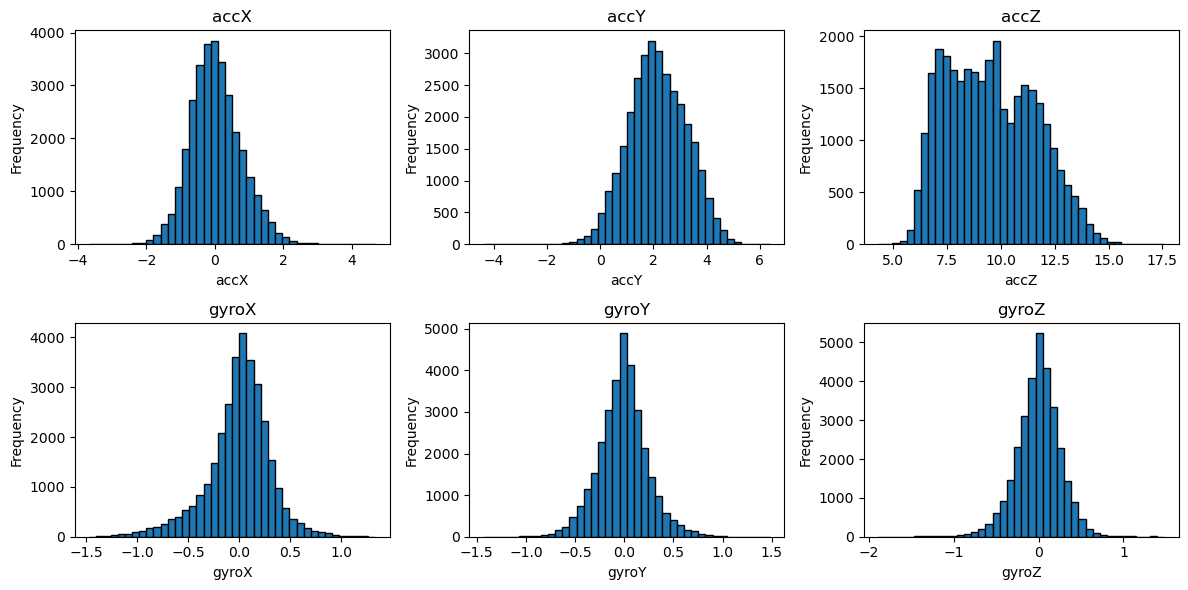

In [13]:
# 9. SENSOR FEATURE DISTRIBUTION


plt.figure(figsize=(12, 6))

for i, col in enumerate(numeric_columns):

    plt.subplot(2, 3, i + 1)

    plt.hist(
        df[col],
        bins=40,
        edgecolor="black"
    )

    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

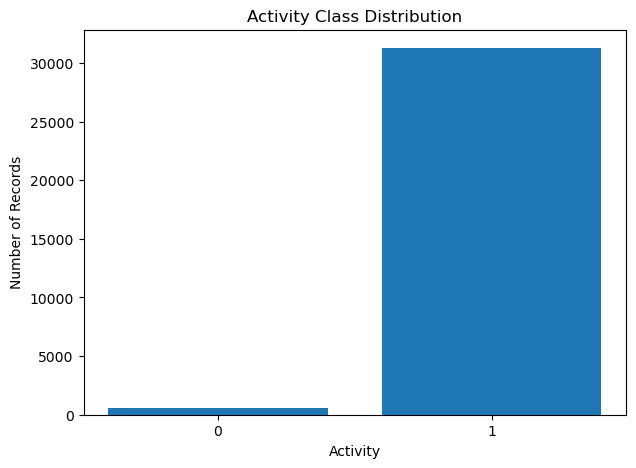

In [14]:
# 10. ACTIVITY DISTRIBUTION


activity_counts = df["Activity"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    activity_counts.index.astype(str),
    activity_counts.values
)

plt.xlabel("Activity")
plt.ylabel("Number of Records")
plt.title("Activity Class Distribution")

plt.show()

<Figure size 800x500 with 0 Axes>

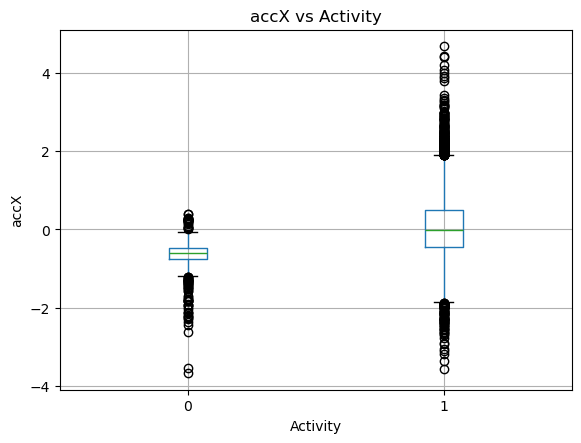

<Figure size 800x500 with 0 Axes>

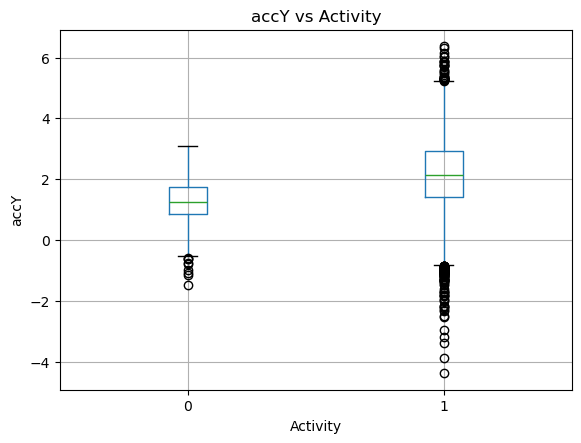

<Figure size 800x500 with 0 Axes>

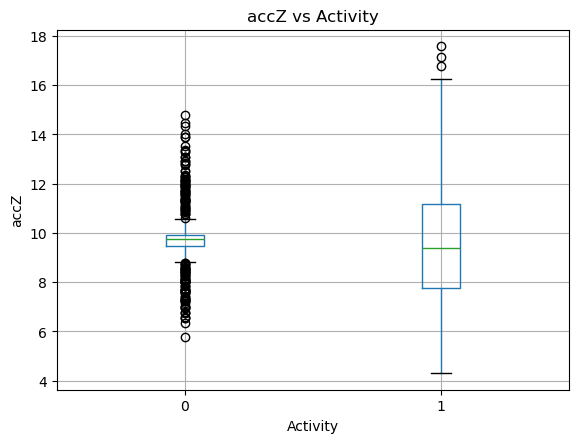

<Figure size 800x500 with 0 Axes>

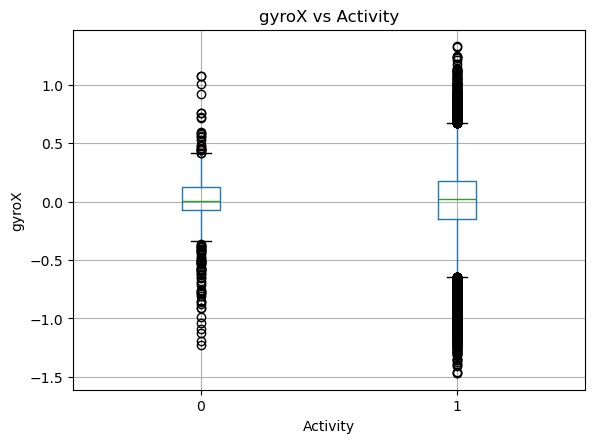

<Figure size 800x500 with 0 Axes>

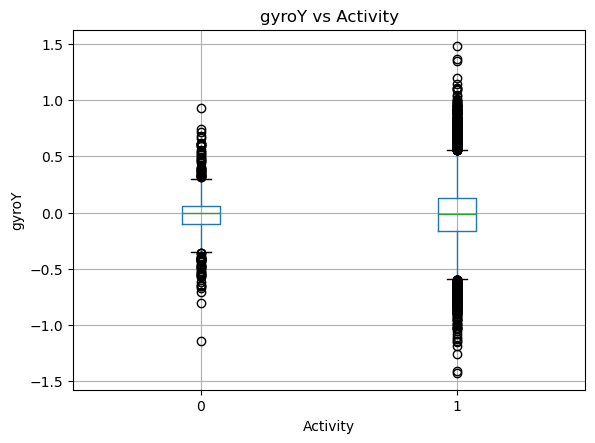

<Figure size 800x500 with 0 Axes>

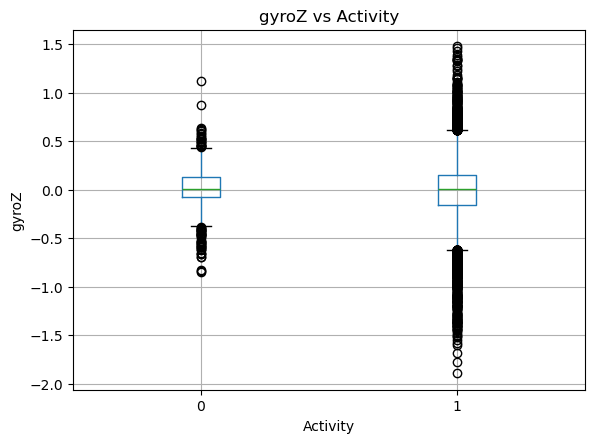

In [15]:
# 11. SENSOR DATA BY ACTIVITY


for col in numeric_columns:

    plt.figure(figsize=(8, 5))

    df.boxplot(
        column=col,
        by="Activity"
    )

    plt.title(f"{col} vs Activity")
    plt.suptitle("")
    plt.xlabel("Activity")
    plt.ylabel(col)

    plt.show()

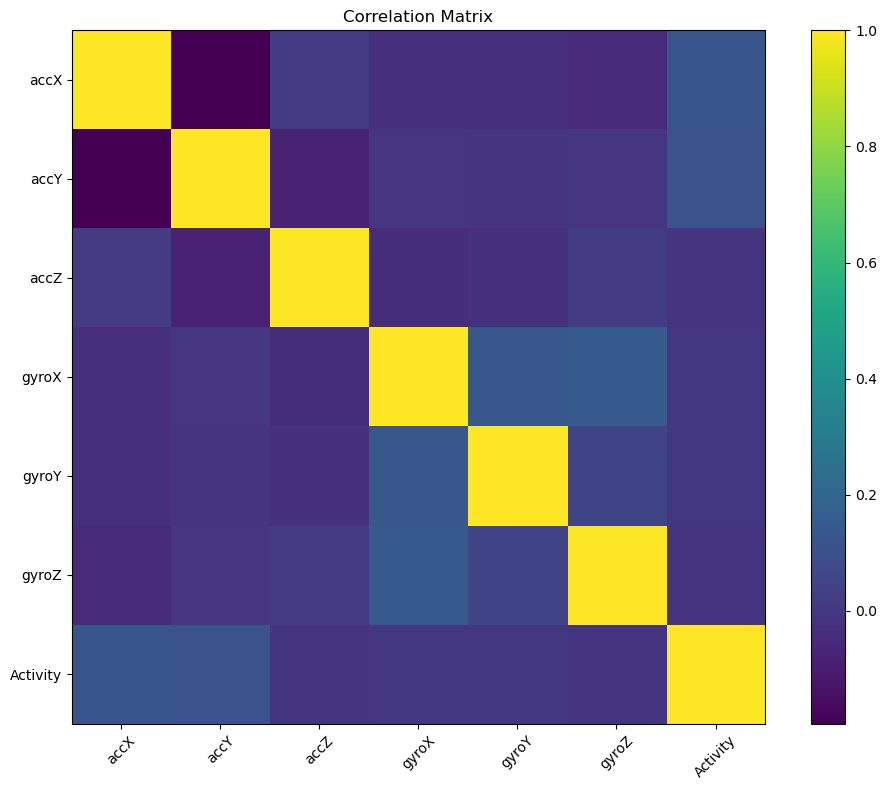

In [16]:
# 12. CORRELATION MATRIX


correlation_columns = numeric_columns + ["Activity"]

corr = df[correlation_columns].corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    corr,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [17]:
# 13. FEATURE ENGINEERING


# Accelerometer magnitude
df["acc_magnitude"] = np.sqrt(
    df["accX"] ** 2 +
    df["accY"] ** 2 +
    df["accZ"] ** 2
)

# Gyroscope magnitude
df["gyro_magnitude"] = np.sqrt(
    df["gyroX"] ** 2 +
    df["gyroY"] ** 2 +
    df["gyroZ"] ** 2
)

print("\nNew features created:")
print("- acc_magnitude")
print("- gyro_magnitude")


New features created:
- acc_magnitude
- gyro_magnitude


In [18]:
# 14. DEFINE FEATURES AND TARGET


features = [
    "accX",
    "accY",
    "accZ",
    "gyroX",
    "gyroY",
    "gyroZ",
    "timestamp_seconds",
    "acc_magnitude",
    "gyro_magnitude"
]

X = df[features]

y = df["Activity"].astype(int)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Feature Shape: (31847, 9)
Target Shape: (31847,)


In [19]:
# 15. TRAIN-TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (25477, 9)
Testing Data: (6370, 9)


In [20]:
# 16. LOGISTIC REGRESSION MODEL


logistic_model = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(
    X_train,
    y_train
)

y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [21]:
# 17. RANDOM FOREST MODEL


rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [22]:
# 18. MODEL EVALUATION FUNCTION


def evaluate_model(
    model_name,
    y_true,
    y_pred,
    y_probability
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_probability
    )

    print("\n" + "=" * 60)

    print(model_name)

    print("=" * 60)

    print(
        f"Accuracy  : {accuracy:.4f}"
    )

    print(
        f"Precision : {precision:.4f}"
    )

    print(
        f"Recall    : {recall:.4f}"
    )

    print(
        f"F1 Score  : {f1:.4f}"
    )

    print(
        f"ROC-AUC   : {auc:.4f}"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    }

In [23]:
# 19. EVALUATE LOGISTIC REGRESSION


lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr,
    y_prob_lr
)




Logistic Regression
Accuracy  : 0.9813
Precision : 0.9841
Recall    : 0.9971
F1 Score  : 0.9906
ROC-AUC   : 0.9733

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.11      0.18       114
           1       0.98      1.00      0.99      6256

    accuracy                           0.98      6370
   macro avg       0.70      0.56      0.58      6370
weighted avg       0.97      0.98      0.98      6370



In [24]:
# 20. EVALUATE RANDOM FOREST


rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf,
    y_prob_rf
)


Random Forest
Accuracy  : 0.9947
Precision : 0.9952
Recall    : 0.9994
F1 Score  : 0.9973
ROC-AUC   : 0.9991

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.74      0.83       114
           1       1.00      1.00      1.00      6256

    accuracy                           0.99      6370
   macro avg       0.97      0.87      0.91      6370
weighted avg       0.99      0.99      0.99      6370



In [25]:
# 21. MODEL COMPARISON


results = pd.DataFrame(
    [
        lr_results,
        rf_results
    ]
)

print("\nModel Comparison:")
print(results)


Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.981319   0.984067  0.997123  0.990552  0.973334
1        Random Forest  0.994662   0.995224  0.999361  0.997288  0.999131


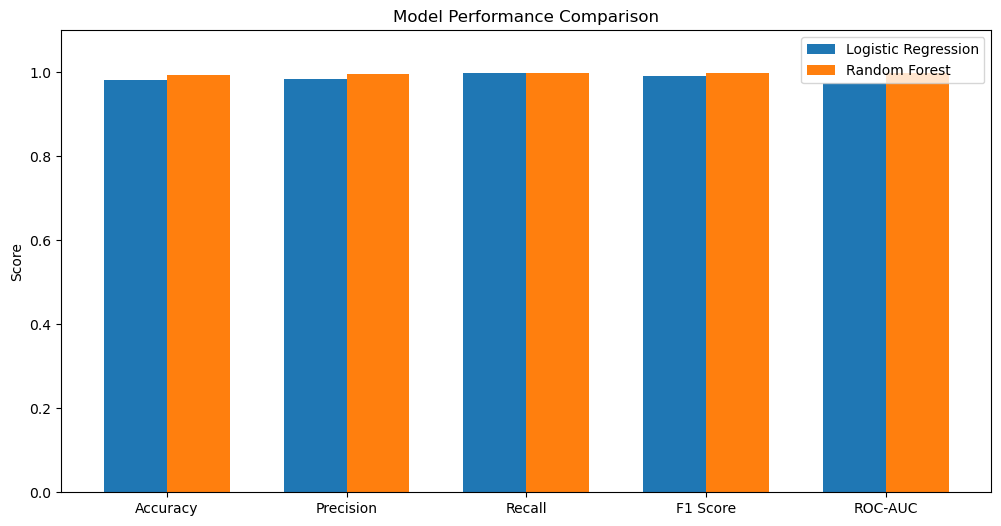

In [26]:
# 22. VISUALIZE MODEL COMPARISON


metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

x = np.arange(len(metrics))

width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    results.iloc[0][metrics],
    width,
    label="Logistic Regression"
)

plt.bar(
    x + width / 2,
    results.iloc[1][metrics],
    width,
    label="Random Forest"
)

plt.xticks(
    x,
    metrics
)

plt.ylim(0, 1.1)

plt.ylabel("Score")
plt.title("Model Performance Comparison")

plt.legend()

plt.show()

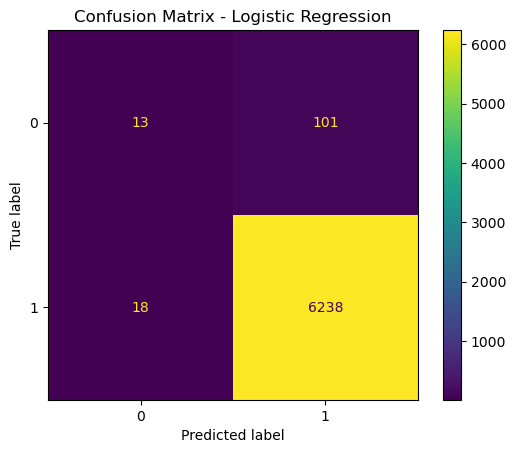

In [27]:
# 23. CONFUSION MATRIX - LOGISTIC REGRESSION


cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr
)

disp_lr.plot()

plt.title(
    "Confusion Matrix - Logistic Regression"
)

plt.show()

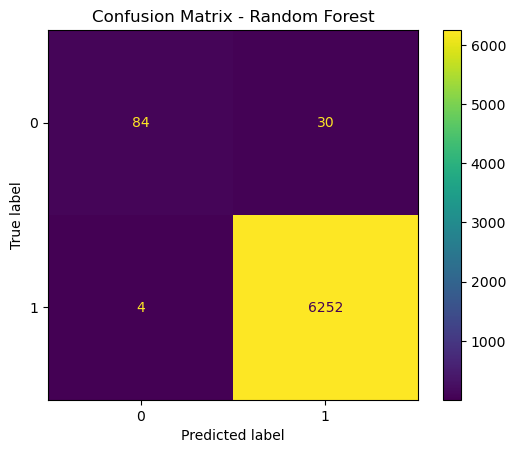

In [28]:
# 24. CONFUSION MATRIX - RANDOM FOREST


cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf
)

disp_rf.plot()

plt.title(
    "Confusion Matrix - Random Forest"
)

plt.show()

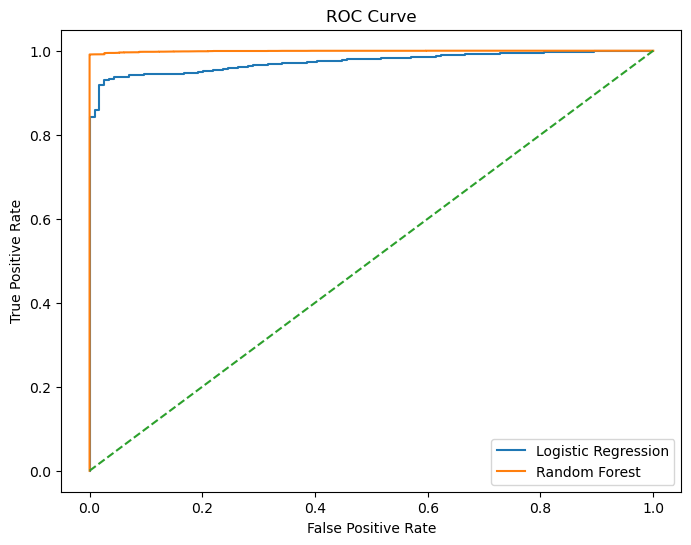

In [29]:
# 25. ROC CURVE


fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob_lr
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label="Logistic Regression"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [30]:
# 26. RANDOM FOREST FEATURE IMPORTANCE


feature_importance = pd.DataFrame(
    {
        "Feature": features,
        "Importance": rf_model.feature_importances_
    }
)

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance)


Feature Importance:
             Feature  Importance
6  timestamp_seconds    0.579984
0               accX    0.163553
1               accY    0.134952
8     gyro_magnitude    0.041815
2               accZ    0.030797
7      acc_magnitude    0.022151
5              gyroZ    0.010777
3              gyroX    0.008626
4              gyroY    0.007345


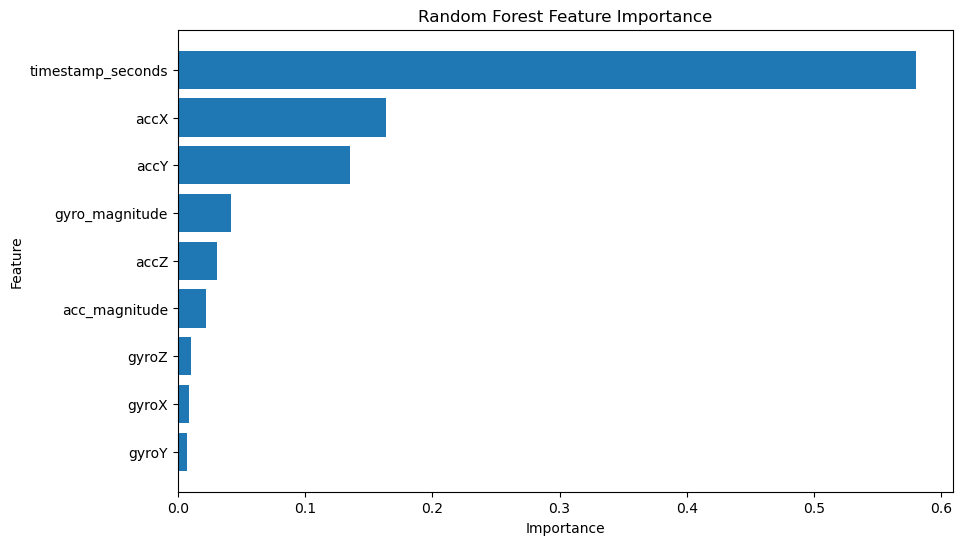

In [31]:
# 27. FEATURE IMPORTANCE VISUALIZATION


plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Random Forest Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()

In [32]:
# 28. SELECT BEST MODEL


best_model_name = results.loc[
    results["F1 Score"].idxmax(),
    "Model"
]

print(
    "\nBest Model based on F1 Score:",
    best_model_name
)


Best Model based on F1 Score: Random Forest


In [33]:
# 29. FINAL PREDICTION FUNCTION


def predict_activity(
    accX,
    accY,
    accZ,
    gyroX,
    gyroY,
    gyroZ,
    timestamp_seconds,
    model=rf_model
):

    acc_magnitude = np.sqrt(
        accX ** 2 +
        accY ** 2 +
        accZ ** 2
    )

    gyro_magnitude = np.sqrt(
        gyroX ** 2 +
        gyroY ** 2 +
        gyroZ ** 2
    )

    input_data = pd.DataFrame(
        [[
            accX,
            accY,
            accZ,
            gyroX,
            gyroY,
            gyroZ,
            timestamp_seconds,
            acc_magnitude,
            gyro_magnitude
        ]],
        columns=features
    )

    prediction = model.predict(
        input_data
    )[0]

    probability = model.predict_proba(
        input_data
    )[0]

    return prediction, probability

In [34]:

# 30. TEST ONE SAMPLE


sample = df.iloc[0]

prediction, probability = predict_activity(
    sample["accX"],
    sample["accY"],
    sample["accZ"],
    sample["gyroX"],
    sample["gyroY"],
    sample["gyroZ"],
    sample["timestamp_seconds"]
)

print("\nSample Prediction:")
print("Predicted Activity:", prediction)
print("Probability:", probability)


Sample Prediction:
Predicted Activity: 1
Probability: [0. 1.]


In [35]:
# 31. FINAL SUMMARY


print("\n" + "=" * 60)
print("PROJECT SUMMARY")
print("=" * 60)

print("Total Records:", len(df))

print("Number of Features:", len(features))

print("\nFeatures Used:")
for feature in features:
    print("-", feature)

print("\nModels Used:")
print("- Logistic Regression")
print("- Random Forest")

print("\nBest Model:", best_model_name)

print("\nFinal Model Results:")
print(results.to_string(index=False))

print("\nProject completed successfully!")


PROJECT SUMMARY
Total Records: 31847
Number of Features: 9

Features Used:
- accX
- accY
- accZ
- gyroX
- gyroY
- gyroZ
- timestamp_seconds
- acc_magnitude
- gyro_magnitude

Models Used:
- Logistic Regression
- Random Forest

Best Model: Random Forest

Final Model Results:
              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
Logistic Regression  0.981319   0.984067 0.997123  0.990552 0.973334
      Random Forest  0.994662   0.995224 0.999361  0.997288 0.999131

Project completed successfully!
